# O problema de Abel.


O problema de Abel é fundamental para diagnósticos ópticos em física de plasma, sendo sua resolução indispensável para a obtenção de grandezas físicas fundamentais, como o perfil de emissividade $(\varepsilon(r))$ em tokamaks. O problema consiste em transformar um objeto matemático simétrico em três dimensões em uma projeção bidimensional. Ademais, é possível fazer o caminho inverso, indo de uma projeção bidimensional para reconstruir um objeto tridimensional; esse problema é denominado problema inverso de Abel.


Em física de plasmas, esse problema aparece ao apontar fibras ópticas para um plasma de simetria cilíndrica. Suponha que queremos obter em um ponto $r$ a emissividade $\varepsilon(r)$. Ao posicionar uma fibra óptica em uma altura $y$ do centro de uma coluna de plasma, ela enxergará toda a radiância $g(y)$ integrada ao longo da corda que seca a coluna. A relação entre a emissividade e a radiância é dada através da Eq. (1).

$$ g(y) = 2 \int^{R_0}_{|y|}\frac{\varepsilon(r)}{\sqrt{y^2-r^2}}r dr \tag{1} $$

A Eq. (1) trata de um problema direto da abel, entretanto, os dados $g(y)$ estão do lado esquerdo da equação enquanto a grandeza desejada em r está dentro do lado esquerdo. Assim é necessário realizar a inversão. A inversão dessa expressão foi analiticamente resolvida por Abel (1823) ao tentar solucionar o problema da curva isocrônica. A inversão analítica é apresentada na Eq. (2).

$$ e(r) = -\frac{1}{\pi}\int^{R_0}_{0}\frac{d g(y)}{dy}\frac{1}{\sqrt{y^2-r^2}} dy \tag{2} $$

Entretanto, apesar da solução análitica para a inversão existir a Eq. (2), a inversão de abel é um problema mal condicionado. Um problema **condicionado**, ou bem posto, é definido pelo critério de Hadamard (1903), através das seguintes condições:

 - Existe solução válida
 - A solução válida é única para as condições propostas
 - A solução é estável e contínua, não apresentando grandes oscilações aos mudar as condições de contorno, ou ao oscilar os dados de entrada

Para demonstrar que o problema de Abel é um problema mal posto, será necessário investigar o comportamento das seguintes funções:

 1) $g(y) = 1600(1-y^2)$
 2) $g(y) = 1- y^4$
 3) $g(y) = 1-3y^2+8y^4-6y^6$

Derivando-as e aplicando a Eq. (2), obtem-se que:

 1) $ e(r) = \frac{3200}{\pi} \sqrt{1 - r^2}$
 2) $ e(r) = \frac{4}{3\pi}(1+2r^2)\sqrt{1-r^2}$
 3) $e(r) = \frac{2\sqrt{1-r^2}}{15\pi} (144r^4 - 88r^2 + 19)$


Vamos aos código!

In [1]:
import numpy as np 
import scipy as sp 
import matplotlib.pyplot as plt 

In [2]:
def erro_relativo(f,g):
    error = 
    

def g(y):
    return 1600*(1-y**2)

def h(y):
    return 1 - y**4

def m(y):
    return 1-3*y**2+8*y**4-6*y**6

In [3]:
n = 1000
y = np.linspace(0,.18,n)

mu = 0.0
sigma = .05

error = np.random.normal(mu,sigma,n)

g_noisy = m(y) + error

e_exact = (2 * np.sqrt(1 - y**2) / (15 * np.pi)) * (144 * y**4 - 88 * y**2 + 19)#(4/(3*np.pi))*np.sqrt(1-y)*(1+2*y**2)#(3200 / np.pi) * np.sqrt(1 - y**2)

In [4]:
dgdy = np.gradient(g_noisy, y)

e_noisy = np.zeros_like(y)

In [5]:
for idx, y_val in enumerate(y[:-1]):
    integrand = dgdy[idx+1:]/np.sqrt(y[idx+1:]**2 - y_val**2)
    e_noisy[idx] = -(1/np.pi)*np.trapz(integrand, y[idx+1:])

/tmp/ipykernel_572/3255501652.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  e_noisy[idx] = -(1/np.pi)*np.trapz(integrand, y[idx+1:])


In [6]:
e_noisy[-1] = 0

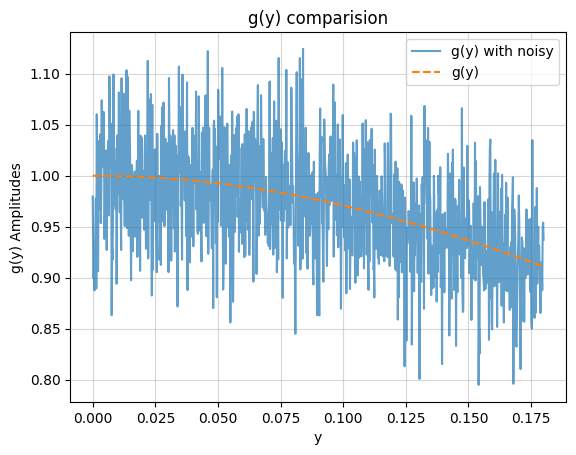

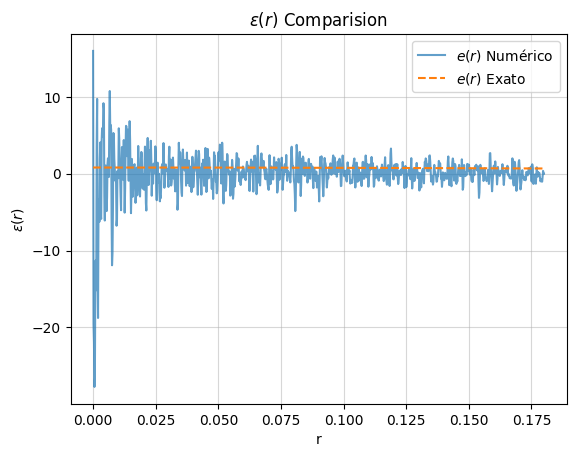

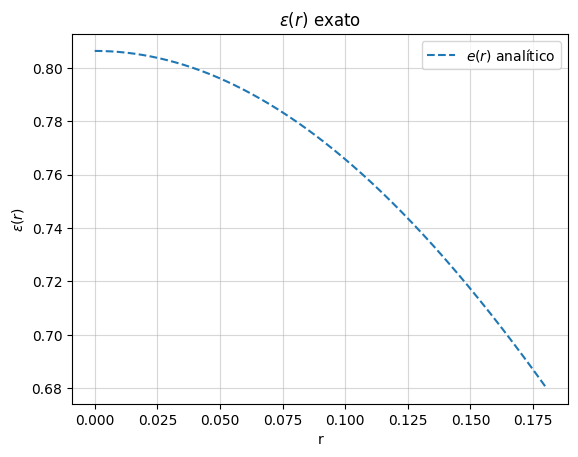

In [7]:
plt.plot(y,g_noisy, alpha = 0.7 , label = r'g(y) with noisy')
plt.plot(y,m(y), ls ='--', label = r'g(y)')
plt.xlabel("y")
plt.ylabel("g(y) Amplitudes")
plt.title("g(y) comparision")
plt.legend()
plt.grid(True, which = "major", alpha = 0.5)
plt.show()

plt.plot(y,e_noisy, ls = '-', alpha = 0.7,label = r'$e(r)$ Numérico')
plt.plot(y,e_exact, ls = '--', label = r'$e(r)$ Exato')
plt.xlabel("r")
plt.ylabel(r"$\varepsilon(r)$")
plt.title(r"$\varepsilon(r)$ Comparision")
plt.legend()
plt.grid(True, which = "major", alpha = 0.5)
plt.show()

plt.plot(y,e_exact, ls = '--', label = r'$e(r)$ analítico')
plt.xlabel("r")
plt.ylabel(r"$\varepsilon(r)$")
plt.title(r"$\varepsilon(r)$ exato")
plt.legend()
plt.grid(True, which = "major", alpha = 0.5)
plt.show()


## O problema da instabilidade

Como é possível observar nos gráficos acima, ao acrescentar um erro na medida $g(y)$ é possível observar que perdemos totalmente a informação do sinal a medida que nos aproximamos do centro devido a contribuição do termo $(y^2-r^2)^{-1/2}$. Logo, observa-se que o problema inverso possui a estabilidade quebrada ao oscilarmos os parâmetros de entrada. Assim, alguns métodos foram desenvolvidos buscando contornar essa situação e minimizar os efeitos dos erros de entrada. Discutiremos alguns adiante.

## Método de Pearse (Onion Peeling)

O método de Pearse, ou *Onion Peeling*, consiste em sincretizar o campos em camadas onde a grandeza desejada seja constante. Defindo uma região ao redor de $r_j$ tal que no intervalo $r_i \pm \frac{\Delta r}{2}$ a grandeza seja constante, semelhante aos discos internos de uma cebola, pode-se escrever a grandeza desejada como:

$$
g(y_i) = \Delta r \sum^{\infty}_{i=j} W_{ij}\varepsilon(r_j) \tag{3}
$$

Onde $W_{ij}$ é a matriz de peso, independente do tamanho do intervalo. $W_{ij}$ tem as seguintes propriedades:

 1) É diagnonal superior
 2) Representa a geometria do problema, representando o comprimento percorrido por uma linha dentro do problema, equivalente ao "quão dentro da cebola" nós estamos da coluna.
 3) É fácilmente resolviveu por eliminação gaussiana
 4) Dada pela seguinte forma.
$$
\mathbf{W}_{ij} = \begin{cases}
0 & j < i \\
[(2j + 1)^2 - 4i^2]^{1/2} & j = i. \\
[(2j + 1)^2 - 4i^2]^{1/2} - [(2j - 1)^2 - 4i^2]^{1/2} & j > i
\end{cases} \tag{4}
$$

A matriz de pesos se relaciona com a matriz de deconvolução através da relação:

$$
D_{ij} = (W^{-1})_{ij} \tag{4}
$$

Que por sua vez, se relaciona com a inversão da seguinte forma:

$$
e(r_i) = \frac{1}{\Delta r}\sum_{i=j}D_{ij} g(y_j) \tag{5}
$$



In [8]:
def onion_peeling_method(n_cordas, y_i):
    """
    Função implementa o método de Pearse, descrito por Dasch (1992), num conjunto de cordas y_i.

    Parâmetros:
    n_cordas (int): número de cordas a ser utilizado no experimento
    r_max (int, float): valor do raio máximo a ser utilizado 

    Retorna:
    W_ij (arr): Matriz de pesos para o caso direto
    D_ij (arr): Matriz de deconvolução para a inversão através da inversão de W_ij
    """
    # Criação da malha 
    dr = y_i[1]-y_i[0]
    
    # Criação dos anéis utilizando o passo
    r_externo = y_i[:]+dr/2
    r_interno = y_i[:]-dr/2
    
    # Tratamento dos valores de borda
    r_externo[-1] = n_cordas*dr
    r_interno[0] = 0
    
    # Criando a matriz W_ij
    W_ij = np.zeros((n_cordas,n_cordas))
    
    # Preenchendo a matriz W_ij
    for i in range(0,n_cordas):
        for j in range(0,n_cordas):
            if r_externo[j] > abs(y_i[i]):
                W_ij[i,j] = 2*(np.sqrt(max(0,r_externo[j]**2-y_i[i]**2))-np.sqrt(max(0,r_interno[j]**2-y_i[i]**2)))
            else:
                W_ij[i,j] = 0
    
    D_ij = np.linalg.inv(W_ij)
    return W_ij, D_ij

In [9]:
r_max = 1
n_cordas = [100,300,400,500,600,700]

D_ij = [[] for i in range(len(n_cordas))]
W_ij = [[] for i in range(len(n_cordas))]
y_i = [[] for i in range(len(n_cordas))]

for idx, n_val in enumerate(n_cordas):
    y_i[idx] = np.linspace(0, r_max, n_val)
    W_ij[idx], D_ij[idx] = onion_peeling_method(n_val, y_i[idx])

In [10]:
m_y_noisy = [[] for i in range(len(n_cordas))]

for i in range(len(n_cordas)):
    error = np.random.normal(mu,sigma,n_cordas[i])
    m_y_noisy[i] = m(y_i[i])

In [11]:
x = np.linspace(0,r_max, n_cordas[2])

e_exata = (2 * np.sqrt(1 - x**2) / (15 * np.pi)) * (144 * x**4 - 88 * x**2 + 19)


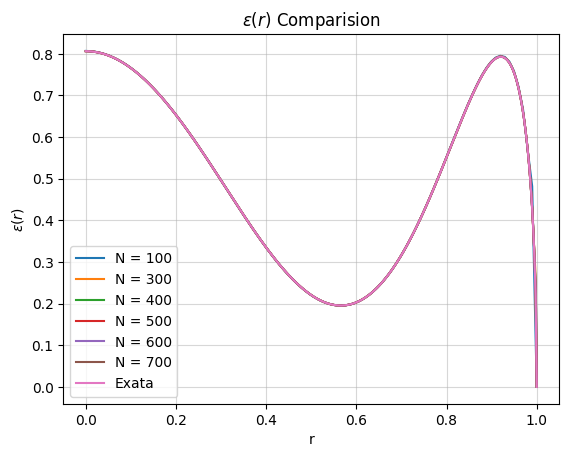

In [12]:
for i in range(len(n_cordas)):
    e_teste = (D_ij[i] @ m_y_noisy[i])
    plt.plot(y_i[i], e_teste,label = f"N = {n_cordas[i]}")
plt.plot(x, e_exata, label = "Exata")
plt.xlabel("r")
plt.ylabel(r"$\varepsilon(r)$")
plt.title(r"$\varepsilon(r)$ Comparision")
plt.legend()
plt.grid(True, which = "major", alpha = 0.5)
plt.show()

Perceba que ainda aplicando o método de Pearse, lidamos com o mesmo ruído! Um das formas de tratar é suavizando o sinal de entrada, 